In [84]:
#Imports
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data Import

In [85]:
from pathlib import Path
import pandas as pd

# -------------------------------------------------
# DATA DIRECTORY
# -------------------------------------------------
DATA_DIR = Path(
    r"C:\Users\anara\Documents\Mestrado Nova IMS\Tese\Data\highD-dataset-v1.0\data"
)

# -------------------------------------------------
# FIND ALL TRACK FILES AND SELECT 40 RECORDINGS
# -------------------------------------------------
track_files = sorted(DATA_DIR.glob("*_tracks.csv"))

# Extract recording IDs like 01, 02, 03...
recording_ids = [f.stem.split("_")[0] for f in track_files]

# Keep the first 40 recordings
selected_ids = recording_ids[:40]

print("Selected recordings:")
for rec_id in selected_ids:
    print("-", rec_id)

# -------------------------------------------------
# LOAD TRACKS, TRACKSMETA, AND RECORDINGMETA
# -------------------------------------------------
tracks_list = []
tracks_meta_list = []
recording_meta_list = []

for rec_id in selected_ids:
    tracks_file = DATA_DIR / f"{rec_id}_tracks.csv"
    tracks_meta_file = DATA_DIR / f"{rec_id}_tracksMeta.csv"
    recording_meta_file = DATA_DIR / f"{rec_id}_recordingMeta.csv"

    tracks = pd.read_csv(tracks_file)
    tracks_meta = pd.read_csv(tracks_meta_file)
    recording_meta = pd.read_csv(recording_meta_file)

    # Add source info to tracks
    tracks["recording_id"] = rec_id
    tracks["source_file"] = tracks_file.name
    tracks["unique_id"] = tracks["recording_id"].astype(str) + "_" + tracks["id"].astype(str)

    # Add source info to tracksMeta
    tracks_meta["recording_id"] = rec_id
    tracks_meta["source_file"] = tracks_meta_file.name
    tracks_meta["unique_id"] = tracks_meta["recording_id"].astype(str) + "_" + tracks_meta["id"].astype(str)

    # Add source info to recordingMeta
    recording_meta["recording_id"] = rec_id
    recording_meta["source_file"] = recording_meta_file.name

    tracks_list.append(tracks)
    tracks_meta_list.append(tracks_meta)
    recording_meta_list.append(recording_meta)

# -------------------------------------------------
# COMBINE EVERYTHING
# -------------------------------------------------
tracks = pd.concat(tracks_list, ignore_index=True)
tracks_meta = pd.concat(tracks_meta_list, ignore_index=True)
recording_meta = pd.concat(recording_meta_list, ignore_index=True)

# -------------------------------------------------
# CHECK RESULTS
# -------------------------------------------------
print("\n=== FILES LOADED SUCCESSFULLY ===")
print("Number of selected recordings:", len(selected_ids))
print("Tracks shape:", tracks.shape)
print("TracksMeta shape:", tracks_meta.shape)
print("RecordingMeta shape:", recording_meta.shape)

print("\n=== TRACK FILES USED ===")
for rec_id in selected_ids:
    print(f"{rec_id}_tracks.csv")

print("\n=== TRACKSMETA FILES USED ===")
for rec_id in selected_ids:
    print(f"{rec_id}_tracksMeta.csv")

print("\n=== RECORDINGMETA FILES USED ===")
for rec_id in selected_ids:
    print(f"{rec_id}_recordingMeta.csv")

# -------------------------------------------------
# BASIC STATISTICS
# -------------------------------------------------
print("\n=== BASIC INFO ===")
print(f"Number of rows (observations): {len(tracks)}")
print(f"Number of vehicles: {tracks['unique_id'].nunique()}")
print(f"Number of lanes: {tracks['laneId'].nunique()}")
print(f"Frame range: {tracks['frame'].min()} → {tracks['frame'].max()}")

print("\n=== VEHICLE TYPES ===")
print(tracks_meta["class"].value_counts())

print("\n=== LANE USAGE ===")
print(tracks["laneId"].value_counts().sort_index())

# -------------------------------------------------
# LANE STABILITY
# -------------------------------------------------
lane_counts = tracks.groupby("unique_id")["laneId"].nunique()

num_lane_stable = (lane_counts == 1).sum()
num_lane_changers = (lane_counts > 1).sum()

print("\n=== LANE STABILITY ===")
print(f"Vehicles total: {len(lane_counts)}")
print(f"Lane-stable vehicles: {num_lane_stable}")
print(f"Lane-changing vehicles: {num_lane_changers}")
print(f"Fraction lane-changing: {num_lane_changers / len(lane_counts):.2%}")

Selected recordings:
- 01
- 02
- 03
- 04
- 05
- 06
- 07
- 08
- 09
- 10
- 11
- 12
- 13
- 14
- 15
- 16
- 17
- 18
- 19
- 20
- 21
- 22
- 23
- 24
- 25
- 26
- 27
- 28
- 29
- 30
- 31
- 32
- 33
- 34
- 35
- 36
- 37
- 38
- 39
- 40

=== FILES LOADED SUCCESSFULLY ===
Number of selected recordings: 40
Tracks shape: (25373095, 28)
TracksMeta shape: (68286, 19)
RecordingMeta shape: (40, 17)

=== TRACK FILES USED ===
01_tracks.csv
02_tracks.csv
03_tracks.csv
04_tracks.csv
05_tracks.csv
06_tracks.csv
07_tracks.csv
08_tracks.csv
09_tracks.csv
10_tracks.csv
11_tracks.csv
12_tracks.csv
13_tracks.csv
14_tracks.csv
15_tracks.csv
16_tracks.csv
17_tracks.csv
18_tracks.csv
19_tracks.csv
20_tracks.csv
21_tracks.csv
22_tracks.csv
23_tracks.csv
24_tracks.csv
25_tracks.csv
26_tracks.csv
27_tracks.csv
28_tracks.csv
29_tracks.csv
30_tracks.csv
31_tracks.csv
32_tracks.csv
33_tracks.csv
34_tracks.csv
35_tracks.csv
36_tracks.csv
37_tracks.csv
38_tracks.csv
39_tracks.csv
40_tracks.csv

=== TRACKSMETA FILES USED ===
01_t

# File Statistics 

In [86]:
# File Statistics - corrected version

print("\n=== BASIC INFO ===")
print(f"Number of rows (observations): {len(tracks)}")
print(f"Number of vehicles: {tracks['unique_id'].nunique()}")
print(f"Number of lanes: {tracks['laneId'].nunique()}")
print(f"Frame range: {tracks['frame'].min()} → {tracks['frame'].max()}")

print("\n=== VEHICLE TYPES ===")
print(tracks_meta["class"].value_counts())

print("\n=== LANE USAGE ===")
print(tracks["laneId"].value_counts().sort_index())

lane_counts = tracks.groupby("unique_id")["laneId"].nunique()

num_lane_stable = (lane_counts == 1).sum()
num_lane_changers = (lane_counts > 1).sum()

print("\n=== LANE CHANGE SUMMARY ===")
print(f"Vehicles total: {len(lane_counts)}")
print(f"Lane-stable vehicles: {num_lane_stable}")
print(f"Lane-changing vehicles: {num_lane_changers}")
print(f"Fraction lane-changing: {num_lane_changers / len(lane_counts):.2%}")


=== BASIC INFO ===
Number of rows (observations): 25373095
Number of vehicles: 68286
Number of lanes: 7
Frame range: 1 → 31274

=== VEHICLE TYPES ===
class
Car      55549
Truck    12737
Name: count, dtype: int64

=== LANE USAGE ===
laneId
2    4359335
3    5338843
4    3434468
5    1151156
6    4353957
7    3857247
8    2878089
Name: count, dtype: int64

=== LANE CHANGE SUMMARY ===
Vehicles total: 68286
Lane-stable vehicles: 60011
Lane-changing vehicles: 8275
Fraction lane-changing: 12.12%


In [87]:
#Info
tracks.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25373095 entries, 0 to 25373094
Data columns (total 28 columns):
 #   Column              Dtype  
---  ------              -----  
 0   frame               int64  
 1   id                  int64  
 2   x                   float64
 3   y                   float64
 4   width               float64
 5   height              float64
 6   xVelocity           float64
 7   yVelocity           float64
 8   xAcceleration       float64
 9   yAcceleration       float64
 10  frontSightDistance  float64
 11  backSightDistance   float64
 12  dhw                 float64
 13  thw                 float64
 14  ttc                 float64
 15  precedingXVelocity  float64
 16  precedingId         int64  
 17  followingId         int64  
 18  leftPrecedingId     int64  
 19  leftAlongsideId     int64  
 20  leftFollowingId     int64  
 21  rightPrecedingId    int64  
 22  rightAlongsideId    int64  
 23  rightFollowingId    int64  
 24  laneId              in

In [88]:

# -------------------------------------------------
# DISPLAY SETTINGS (show everything)
# -------------------------------------------------
pd.set_option('display.max_columns', None)      # show all columns
pd.set_option('display.width', None)            # prevent line wrapping
pd.set_option('display.max_colwidth', None)     # show full column content
pd.set_option('display.max_rows', None)         # optional: show all rows (careful if large!)

# -------------------------------------------------
# SHOW FULL DATAFRAME
# -------------------------------------------------
print("\n=== FULL DATAFRAME (FIRST ROWS) ===")
print(tracks.head().to_string())

# -------------------------------------------------
# SHOW COLUMN NAMES
# -------------------------------------------------
print("\n=== COLUMN NAMES ===")
for col in tracks.columns:
    print(col)

# -------------------------------------------------
# SHOW FULL DESCRIPTIVE STATISTICS
# -------------------------------------------------
print("\n=== DESCRIBE (ALL NUMERIC COLUMNS) ===")
print(tracks.describe().to_string())

# -------------------------------------------------
# SHOW FULL DATAFRAME INFO
# -------------------------------------------------
print("\n=== DATAFRAME INFO ===")
tracks.info()


=== FULL DATAFRAME (FIRST ROWS) ===
   frame  id       x      y  width  height  xVelocity  yVelocity  xAcceleration  yAcceleration  frontSightDistance  backSightDistance  dhw  thw  ttc  precedingXVelocity  precedingId  followingId  leftPrecedingId  leftAlongsideId  leftFollowingId  rightPrecedingId  rightAlongsideId  rightFollowingId  laneId recording_id    source_file unique_id
0      1   1  362.26  21.68   4.85    2.12      40.85       0.00           0.30            0.0               48.05             363.77  0.0  0.0  0.0                 0.0            0            3                0                0                0                 0                 0                 6       5           01  01_tracks.csv      01_1
1      2   1  363.73  21.68   4.85    2.12      40.87       0.00           0.30            0.0               46.54             365.28  0.0  0.0  0.0                 0.0            0           14                0                0                0                 0        

In [89]:
# Variables with missing values and their percentage
na_percentages = tracks.isna().mean().sort_values(ascending=False) * 100
na_percentages = na_percentages.round(2)
na_percentages[na_percentages>0]


Series([], dtype: float64)

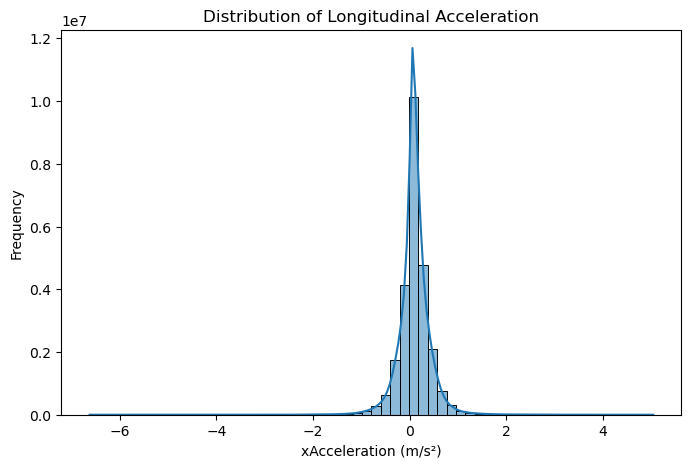

In [90]:

plt.figure(figsize=(8,5))
sns.histplot(tracks["xAcceleration"], bins=60, kde=True)
plt.title("Distribution of Longitudinal Acceleration")
plt.xlabel("xAcceleration (m/s²)")
plt.ylabel("Frequency")
plt.show()

In [91]:
# -----------------------------
# RAW VELOCITY STATS (SIGNED)
# -----------------------------
# xVelocity is SIGNED in highD (direction). Negative values are valid.
print("\n=== RAW xVelocity STATISTICS (m/s, SIGNED) ===")
print(tracks["xVelocity"].describe())

print("\n=== RAW xVelocity STATISTICS (km/h, SIGNED) ===")
print((tracks["xVelocity"] * 3.6).describe())


# -----------------------------
# HUMAN-FRIENDLY SPEED STATS (MAGNITUDE)
# -----------------------------
# For human interpretation (and to match the visualizer), use speed magnitude |xVelocity|.
# No sentinel replacement is applied here.
tracks_clean = tracks.copy()

tracks_clean["speed_ms"] = tracks_clean["xVelocity"].abs()
tracks_clean["speed_kmh"] = tracks_clean["speed_ms"] * 3.6

print("\n=== SPEED STATISTICS (m/s, MAGNITUDE) ===")
print(tracks_clean["speed_ms"].describe())

print("\n=== SPEED STATISTICS (km/h, MAGNITUDE) ===")
print(tracks_clean["speed_kmh"].describe())


=== RAW xVelocity STATISTICS (m/s, SIGNED) ===
count    2.537310e+07
mean     5.015123e-01
std      2.817893e+01
min     -6.400000e+01
25%     -2.664000e+01
50%     -6.290000e+00
75%      2.832000e+01
max      6.828000e+01
Name: xVelocity, dtype: float64

=== RAW xVelocity STATISTICS (km/h, SIGNED) ===
count    2.537310e+07
mean     1.805444e+00
std      1.014442e+02
min     -2.304000e+02
25%     -9.590400e+01
50%     -2.264400e+01
75%      1.019520e+02
max      2.458080e+02
Name: xVelocity, dtype: float64

=== SPEED STATISTICS (m/s, MAGNITUDE) ===
count    2.537310e+07
mean     2.714733e+01
std      7.571408e+00
min      0.000000e+00
25%      2.345000e+01
50%      2.754000e+01
75%      3.245000e+01
max      6.828000e+01
Name: speed_ms, dtype: float64

=== SPEED STATISTICS (km/h, MAGNITUDE) ===
count    2.537310e+07
mean     9.773039e+01
std      2.725707e+01
min      0.000000e+00
25%      8.442000e+01
50%      9.914400e+01
75%      1.168200e+02
max      2.458080e+02
Name: speed_kmh, 

# Lane changers cleanup

In [92]:
# Cleanup lane changers

# -------------------------------------------------
# ORIGINAL FRAME SPAN PER EGO VEHICLE
# -------------------------------------------------
ego_frame_span = (
    tracks.groupby("unique_id")["frame"]
    .agg(orig_start_frame="min", orig_end_frame="max")
    .reset_index()
)

# -----------------------------
# STEP 1: Identify lane-stable vehicles
# -----------------------------
lane_nunique = tracks.groupby("unique_id")["laneId"].nunique()
lane_stable_ids = set(lane_nunique[lane_nunique == 1].index)
lane_changer_ids = set(lane_nunique[lane_nunique > 1].index)

total_vehicles = tracks["unique_id"].nunique()
num_stable = len(lane_stable_ids)
num_changers = len(lane_changer_ids)

print("\n=== LANE STABILITY ===")
print("Vehicles total:", total_vehicles)
print("Lane-stable vehicles:", num_stable)
print("Lane-changing vehicles:", num_changers)
print(f"Fraction lane-changing: {num_changers / total_vehicles:.2%}")


=== LANE STABILITY ===
Vehicles total: 68286
Lane-stable vehicles: 60011
Lane-changing vehicles: 8275
Fraction lane-changing: 12.12%


In [93]:
leader_lookup = tracks.loc[
    tracks["id"] != 0,
    ["recording_id", "frame", "id", "laneId"]
].rename(
    columns={"id": "precedingId", "laneId": "precedingLaneId"}
)

df = tracks.merge(
    leader_lookup,
    on=["recording_id", "frame", "precedingId"],
    how="left"
)

print(
    "Rows with leader but missing leader lane:",
    ((df["precedingId"] != 0) & df["precedingLaneId"].isna()).sum()
)

Rows with leader but missing leader lane: 0


In [94]:
# -----------------------------
# STEP 3: Strict validity mask (frame-level)
# -----------------------------

df["preceding_unique_id"] = (
    df["recording_id"].astype(str) + "_" + df["precedingId"].astype(str)
)

df["ego_lane_stable"] = df["unique_id"].isin(lane_stable_ids)

df["lead_lane_stable"] = (
    (df["precedingId"] != 0)
    & df["preceding_unique_id"].isin(lane_stable_ids)
)

df["leader_exists"] = df["precedingId"] != 0
df["leader_present_same_frame"] = df["precedingLaneId"].notna()
df["same_lane_as_leader"] = df["laneId"] == df["precedingLaneId"]

df["valid_cf_frame"] = (
    df["ego_lane_stable"]
    & df["leader_exists"]
    & df["lead_lane_stable"]
    & df["leader_present_same_frame"]
    & df["same_lane_as_leader"]
)

In [95]:
MIN_EPISODE_SECONDS = 5.0   # or 2.0 if you want to relax it
DEFAULT_FRAMERATE = 25

# -----------------------------
# STEP 4: Segment into episodes with constant leader
# -----------------------------
df = df.sort_values(["unique_id", "frame"]).copy()

valid_change = df["valid_cf_frame"] != df.groupby("unique_id")["valid_cf_frame"].shift(1)
leader_change = df["preceding_unique_id"] != df.groupby("unique_id")["preceding_unique_id"].shift(1)

df["run_break"] = (valid_change | leader_change).fillna(True)
df["run_id"] = df.groupby("unique_id")["run_break"].cumsum()

df_valid = df[df["valid_cf_frame"]].copy()

episodes = (
    df_valid.groupby(["unique_id", "run_id"], as_index=False)
    .agg(
        recording_id=("recording_id", "first"),
        id=("id", "first"),
        precedingId=("precedingId", "first"),
        preceding_unique_id=("preceding_unique_id", "first"),
        laneId=("laneId", "first"),
        start_frame=("frame", "min"),
        end_frame=("frame", "max"),
        n_frames=("frame", "size"),
    )
)

min_frames = int(np.ceil(MIN_EPISODE_SECONDS * DEFAULT_FRAMERATE))
episodes["duration_s"] = episodes["n_frames"] / DEFAULT_FRAMERATE

episodes_strict = episodes[episodes["n_frames"] >= min_frames].copy()

print("\n=== STRICT EPISODES ===")
print("Min episode seconds:", MIN_EPISODE_SECONDS)
print("Min frames:", min_frames)
print("Episodes found:", len(episodes_strict))
print("Unique egos with episodes:", episodes_strict["unique_id"].nunique())


=== STRICT EPISODES ===
Min episode seconds: 5.0
Min frames: 125
Episodes found: 49811
Unique egos with episodes: 49803


In [96]:
# -----------------------------
# STEP 5: Attach episode_id back to per-frame data
# -----------------------------
episodes_strict = episodes_strict.copy()  # avoids SettingWithCopy warnings

episodes_strict["kept_start_frame"] = episodes_strict["start_frame"]
episodes_strict["kept_end_frame"] = episodes_strict["end_frame"]

# Add original ego frame span
episodes_strict = episodes_strict.merge(
    ego_frame_span,
    on="unique_id",
    how="left"
)

# Fraction of ego trajectory covered by this episode
episodes_strict["kept_fraction_of_ego"] = (
    (episodes_strict["kept_end_frame"] - episodes_strict["kept_start_frame"] + 1)
    / (episodes_strict["orig_end_frame"] - episodes_strict["orig_start_frame"] + 1)
)

# Create a unique episode id
episodes_strict = episodes_strict.reset_index(drop=True)
episodes_strict["episode_id"] = np.arange(len(episodes_strict))

# Attach episode_id to frame-level data (only kept frames)
episode_key = episodes_strict[["unique_id", "run_id", "episode_id"]]
episode_tracks = df_valid.merge(episode_key, on=["unique_id", "run_id"], how="inner")

# Propagate episode-level context to each frame row (useful later)
episode_tracks = episode_tracks.merge(
    episodes_strict[
        [
            "episode_id",
            "orig_start_frame", "orig_end_frame",
            "kept_start_frame", "kept_end_frame",
            "kept_fraction_of_ego",
            "duration_s", "n_frames"
        ]
    ],
    on="episode_id",
    how="left"
)

In [97]:
# ============================================================
# STEP 6 — OUTPUT CHECKS
# ============================================================
total_frames = len(tracks)
total_vehicles = tracks["unique_id"].nunique()

kept_frames = len(episode_tracks)
kept_egos = episode_tracks["unique_id"].nunique()

print("\n=== CLEANED FRAME DATA ===")
print("Frames kept:", kept_frames, f"({kept_frames / total_frames:.2%} of all frames)")
print("Unique egos kept (in episodes):", kept_egos, f"({kept_egos / total_vehicles:.2%} of all vehicles)")
print("Unique leaders in episodes:", episode_tracks["preceding_unique_id"].nunique())

print("\n=== EPISODE DURATION SUMMARY (seconds) ===")
print(episodes_strict["duration_s"].describe().to_string())

print("\nSample episodes (first 20):")
show_cols = [
    "episode_id", "recording_id", "id", "unique_id",
    "precedingId", "preceding_unique_id", "laneId",
    "orig_start_frame", "orig_end_frame",
    "kept_start_frame", "kept_end_frame",
    "duration_s", "n_frames", "kept_fraction_of_ego"
]
print(episodes_strict[show_cols].head(20).to_string(index=False))


=== CLEANED FRAME DATA ===
Frames kept: 15832633 (62.40% of all frames)
Unique egos kept (in episodes): 49803 (72.93% of all vehicles)
Unique leaders in episodes: 49803

=== EPISODE DURATION SUMMARY (seconds) ===
count    49811.000000
mean        12.714166
std          6.039404
min          5.000000
25%          9.840000
50%         11.800000
75%         14.280000
max         86.000000

Sample episodes (first 20):
 episode_id recording_id   id unique_id  precedingId preceding_unique_id  laneId  orig_start_frame  orig_end_frame  kept_start_frame  kept_end_frame  duration_s  n_frames  kept_fraction_of_ego
          0           01   10     01_10            6                01_6       6                 1             232                 1             185        7.40       185              0.797414
          1           01 1000   01_1000          999              01_999       3             21549           21784             21549           21753        8.20       205              0.868644
  

##Outliers


In [98]:
print("\n=== xAcceleration Percentiles ===")
print(tracks["xAcceleration"].describe(
    percentiles=[0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999]
).to_string())

print("\n=== xVelocity Percentiles ===")
print(tracks["xVelocity"].describe(
    percentiles=[0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999]
).to_string())

print("\n=== dhw Percentiles ===")
print(tracks["dhw"].describe(
    percentiles=[0.01, 0.05, 0.95, 0.99]
).to_string())

print("\n=== ttc Percentiles ===")
print(tracks["ttc"].describe(
    percentiles=[0.01, 0.05, 0.95, 0.99]
).to_string())


=== xAcceleration Percentiles ===
count    2.537310e+07
mean     9.871646e-02
std      3.237563e-01
min     -6.630000e+00
0.1%    -1.660000e+00
1%      -8.200000e-01
5%      -3.900000e-01
50%      9.000000e-02
95%      5.900000e-01
99%      1.000000e+00
99.9%    1.990000e+00
max      5.050000e+00

=== xVelocity Percentiles ===
count    2.537310e+07
mean     5.015123e-01
std      2.817893e+01
min     -6.400000e+01
0.1%    -4.744000e+01
1%      -4.025000e+01
5%      -3.542000e+01
50%     -6.290000e+00
95%      3.569000e+01
99%      4.033000e+01
99.9%    4.780000e+01
max      6.828000e+01

=== dhw Percentiles ===
count    2.537310e+07
mean     4.561861e+01
std      5.019225e+01
min      0.000000e+00
1%       0.000000e+00
5%       0.000000e+00
50%      3.160000e+01
95%      1.494100e+02
99%      2.376700e+02
max      4.079600e+02

=== ttc Percentiles ===
count    2.537310e+07
mean    -1.017088e+00
std      1.144287e+05
min     -3.597793e+08
1%      -1.050060e+03
5%      -2.079400e+02
50% 

In [99]:
import numpy as np
import pandas as pd

# Use only valid car-following frames (recommended)
tracks_cf = df[df["valid_cf_frame"]].copy()

all_numeric_cols = tracks_cf.select_dtypes(include=[np.number]).columns.tolist()

exclude_cols = [
    "id", "precedingId", "followingId",
    "leftPrecedingId", "leftFollowingId",
    "rightPrecedingId", "rightFollowingId",
    "rightAlongsideId", "leftAlongsideId",
    "laneId",
    "frame", "recording_id", "run_id", "episode_id"
]

numeric_cols = [c for c in all_numeric_cols if c not in exclude_cols]

print("Numeric columns used:")
print(numeric_cols)

outlier_summary = []

for col in numeric_cols:
    Q1 = tracks_cf[col].quantile(0.25)
    Q3 = tracks_cf[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = tracks_cf[
        (tracks_cf[col] < lower_bound) | (tracks_cf[col] > upper_bound)
    ]

    outlier_summary.append({
        "variable": col,
        "num_outliers": len(outliers),
        "percent_outliers": 100 * len(outliers) / len(tracks_cf),
        "min_value": tracks_cf[col].min(),
        "max_value": tracks_cf[col].max()
    })

outlier_df = pd.DataFrame(outlier_summary).sort_values(
    "percent_outliers", ascending=False
)

print(outlier_df.to_string(index=False))

Numeric columns used:
['x', 'y', 'width', 'height', 'xVelocity', 'yVelocity', 'xAcceleration', 'yAcceleration', 'frontSightDistance', 'backSightDistance', 'dhw', 'thw', 'ttc', 'precedingXVelocity', 'precedingLaneId']
          variable  num_outliers  percent_outliers     min_value    max_value
             width       3120074         19.226010  2.320000e+00        23.24
               ttc       2436387         15.013106 -1.256361e+08 288276598.90
               dhw       1213503          7.477650  6.400000e-01       407.96
     xAcceleration       1157989          7.135571 -6.630000e+00         5.05
               thw       1088050          6.704604 -5.749723e+05    278657.81
     yAcceleration        771298          4.752766 -7.000000e-01         0.73
         yVelocity        437394          2.695238 -1.350000e+00         1.50
            height         61479          0.378836  1.520000e+00         3.33
                 x             0          0.000000  4.300000e-01       408.76
   

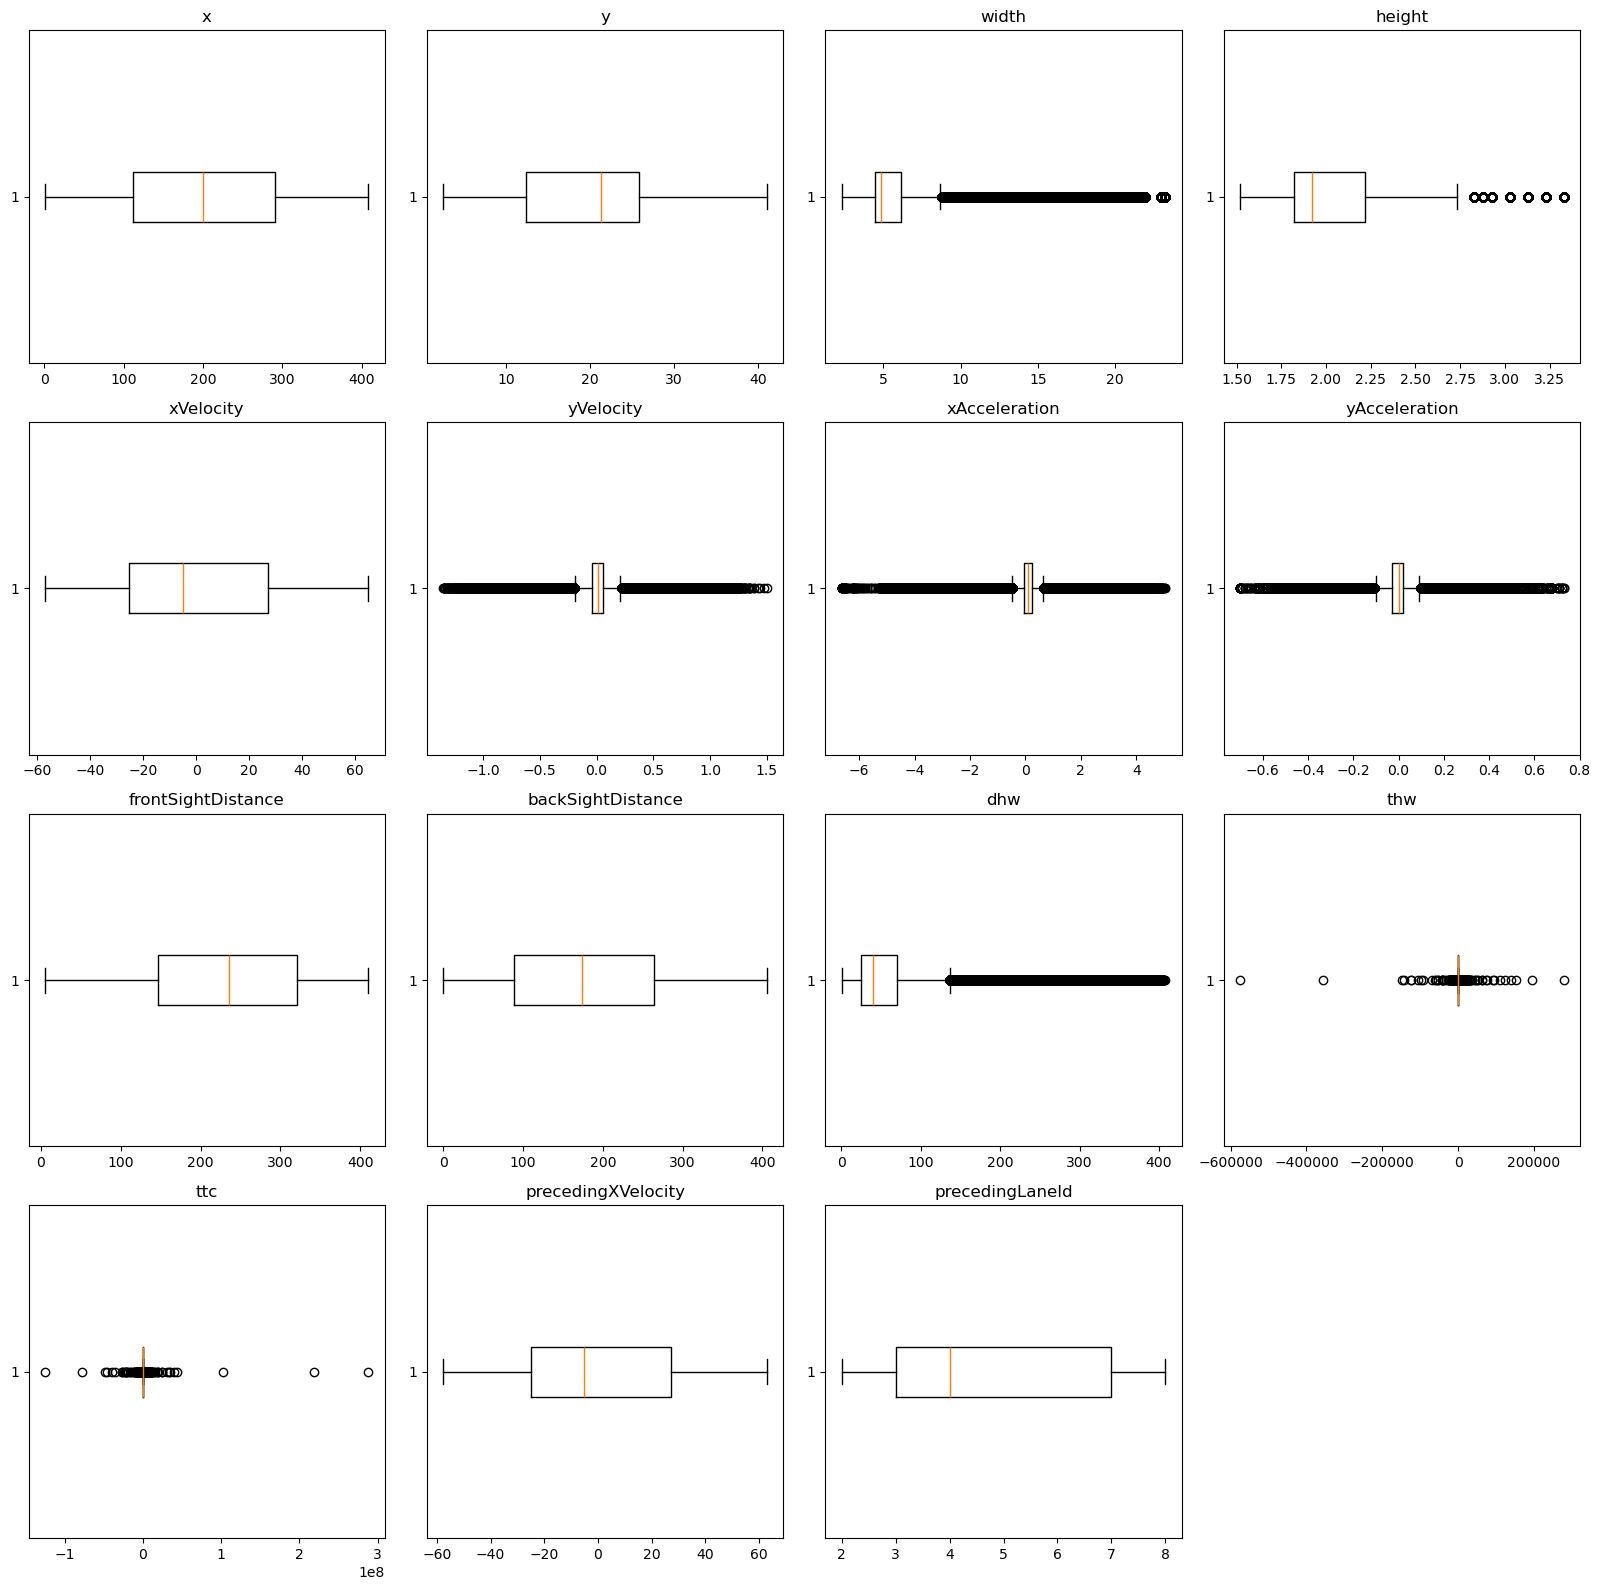

In [100]:
import matplotlib.pyplot as plt
import math

# Recommended: use only valid car-following frames
tracks_cf = df[df["valid_cf_frame"]].copy()

# Recompute numeric columns from cleaned CF data
all_numeric_cols = tracks_cf.select_dtypes(include=["number"]).columns.tolist()

exclude_cols = [
    "id", "precedingId", "followingId",
    "leftPrecedingId", "leftFollowingId",
    "rightPrecedingId", "rightFollowingId",
    "rightAlongsideId", "leftAlongsideId",
    "laneId", "frame", "run_id", "episode_id"
]

numeric_cols_clean = [c for c in all_numeric_cols if c not in exclude_cols]

n_cols = 4
n_rows = math.ceil(len(numeric_cols_clean) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numeric_cols_clean):
    axes[i].boxplot(tracks_cf[col].dropna(), vert=False)
    axes[i].set_title(col)

# Hide unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [101]:
print("\n=== xAcceleration Percentiles ===")
print(tracks["xAcceleration"].describe(
    percentiles=[0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999]
).to_string())

print("\n=== xVelocity Percentiles ===")
print(tracks["xVelocity"].describe(
    percentiles=[0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999]
).to_string())

print("\n=== dhw Percentiles ===")
print(tracks["dhw"].describe(
    percentiles=[0.01, 0.05, 0.95, 0.99]
).to_string())

print("\n=== ttc Percentiles ===")
print(tracks["ttc"].describe(
    percentiles=[0.01, 0.05, 0.95, 0.99]
).to_string())


=== xAcceleration Percentiles ===
count    2.537310e+07
mean     9.871646e-02
std      3.237563e-01
min     -6.630000e+00
0.1%    -1.660000e+00
1%      -8.200000e-01
5%      -3.900000e-01
50%      9.000000e-02
95%      5.900000e-01
99%      1.000000e+00
99.9%    1.990000e+00
max      5.050000e+00

=== xVelocity Percentiles ===
count    2.537310e+07
mean     5.015123e-01
std      2.817893e+01
min     -6.400000e+01
0.1%    -4.744000e+01
1%      -4.025000e+01
5%      -3.542000e+01
50%     -6.290000e+00
95%      3.569000e+01
99%      4.033000e+01
99.9%    4.780000e+01
max      6.828000e+01

=== dhw Percentiles ===
count    2.537310e+07
mean     4.561861e+01
std      5.019225e+01
min      0.000000e+00
1%       0.000000e+00
5%       0.000000e+00
50%      3.160000e+01
95%      1.494100e+02
99%      2.376700e+02
max      4.079600e+02

=== ttc Percentiles ===
count    2.537310e+07
mean    -1.017088e+00
std      1.144287e+05
min     -3.597793e+08
1%      -1.050060e+03
5%      -2.079400e+02
50% 

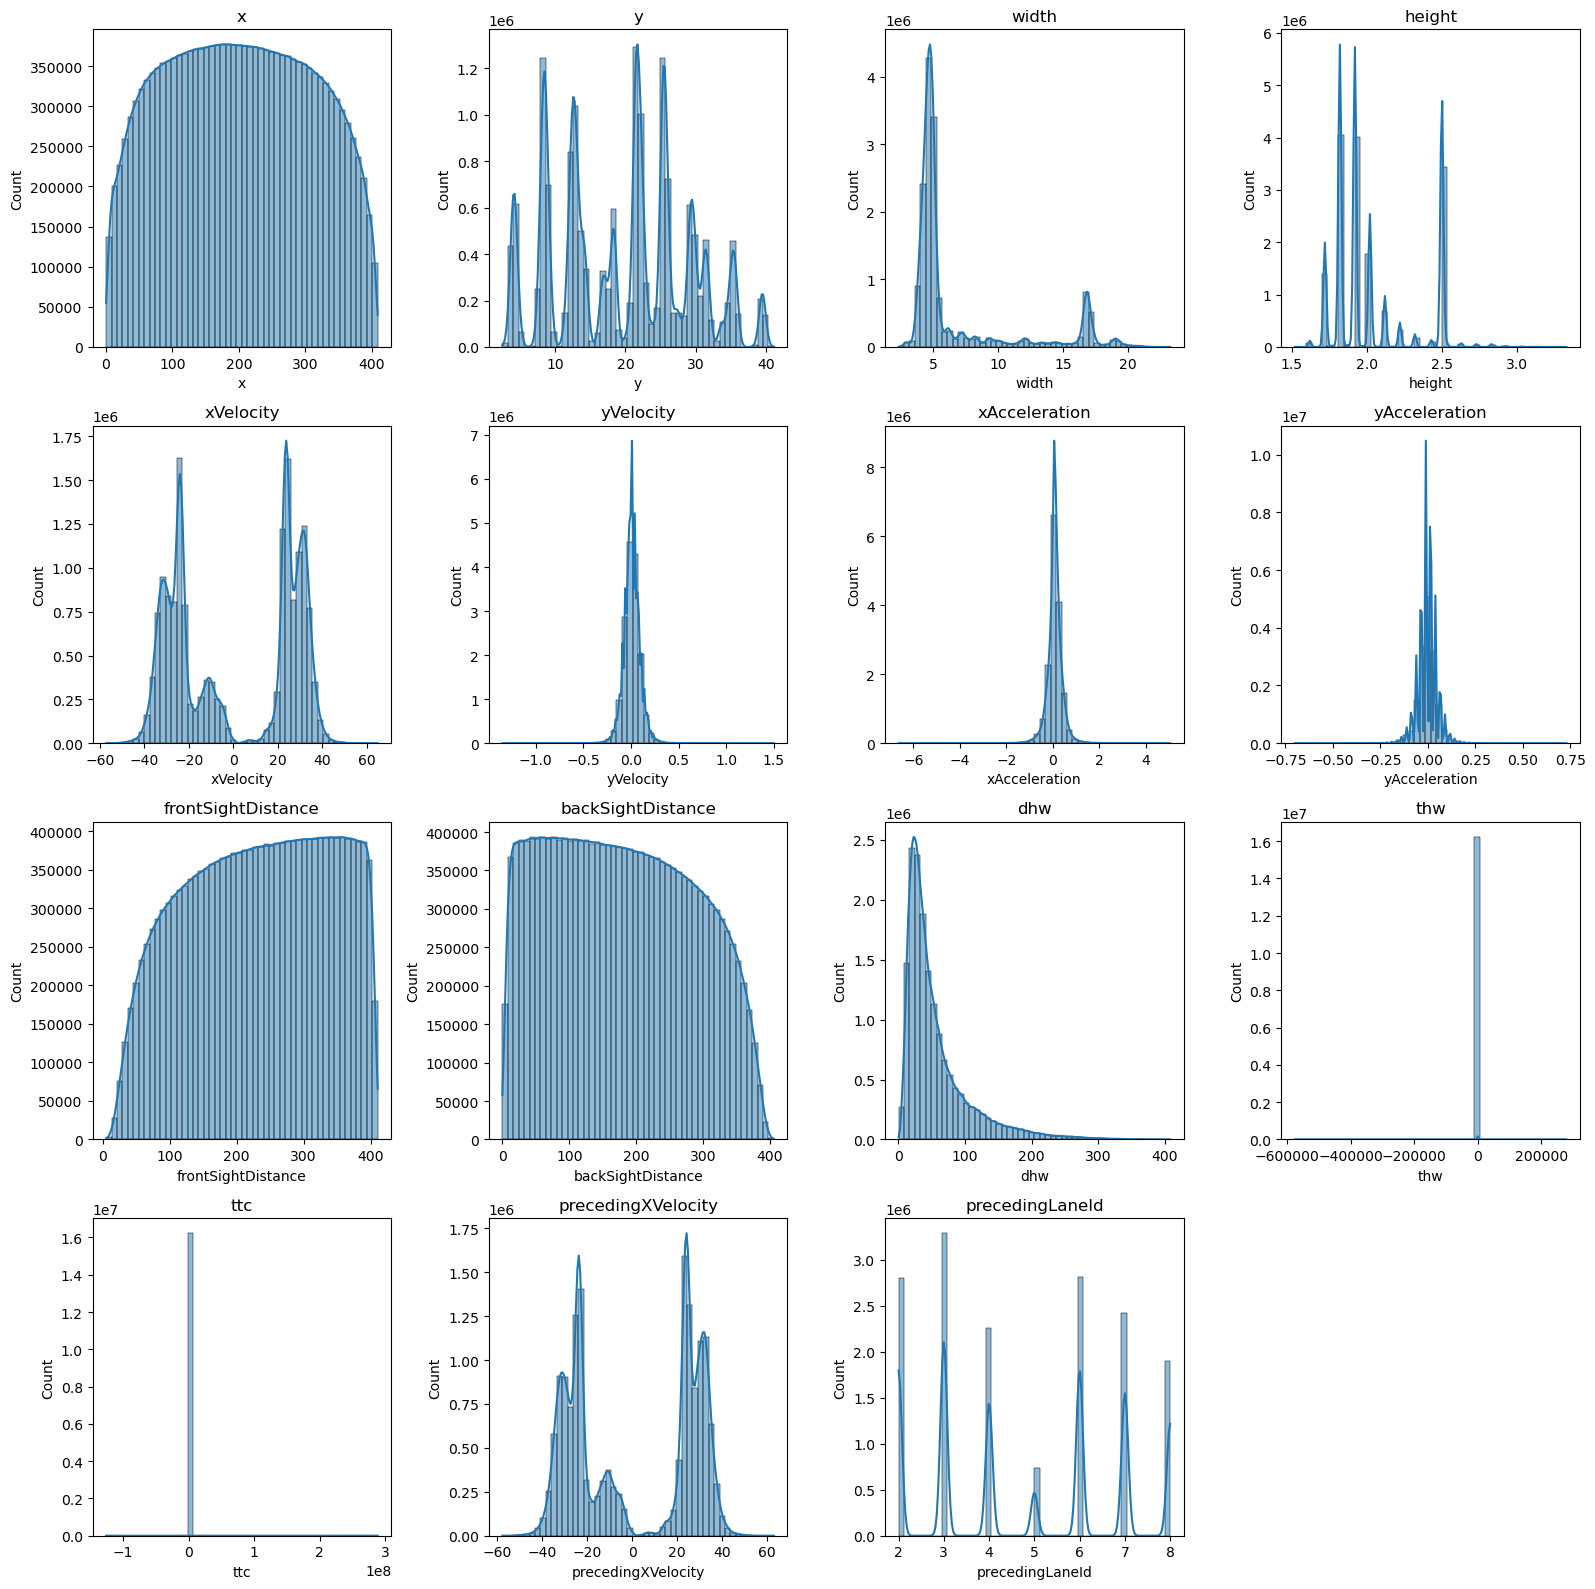

In [102]:
import seaborn as sns
import matplotlib.pyplot as plt
import math

# Use clean car-following data
tracks_cf = df[df["valid_cf_frame"]].copy()

n_cols = 4
n_rows = math.ceil(len(numeric_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(tracks_cf[col].dropna(), bins=50, kde=True, ax=axes[i])
    axes[i].set_title(col)

# Remove unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Dataset separation - 80-20

##Data Output


In [103]:
# ============================================================
# STEP 7 — SAVE CLEANED DATASET WITH EGO-LEVEL / EPISODE-CONSISTENT SPLIT
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

OUTPUT_DIR = Path("processed_data")
OUTPUT_DIR.mkdir(exist_ok=True)

# -------------------------------------------------
# SPLIT SETTINGS
# -------------------------------------------------
RANDOM_SEED = 42

train_frac = 0.70
val_frac = 0.15
test_frac = 0.15

assert abs(train_frac + val_frac + test_frac - 1.0) < 1e-9, "Fractions must sum to 1."

episodes_strict = episodes_strict.copy()
episode_tracks = episode_tracks.copy()

# -------------------------------------------------
# 1) EGO-LEVEL SPLIT
#    all episodes of the same ego vehicle stay together
# -------------------------------------------------
unique_egos = episodes_strict["unique_id"].drop_duplicates().to_numpy()

rng = np.random.default_rng(RANDOM_SEED)
shuffled_egos = rng.permutation(unique_egos)

n_egos = len(shuffled_egos)
n_train = int(n_egos * train_frac)
n_val = int(n_egos * val_frac)
n_test = n_egos - n_train - n_val

train_egos = set(shuffled_egos[:n_train])
val_egos = set(shuffled_egos[n_train:n_train + n_val])
test_egos = set(shuffled_egos[n_train + n_val:])

def assign_split(unique_id):
    if unique_id in train_egos:
        return "train"
    elif unique_id in val_egos:
        return "val"
    else:
        return "test"

# Assign split to episodes through ego vehicle
episodes_strict["split"] = episodes_strict["unique_id"].apply(assign_split)

# -------------------------------------------------
# 2) ATTACH SPLIT TO FRAME-LEVEL DATA
#    each frame inherits split from its episode
# -------------------------------------------------
episode_tracks = episode_tracks.merge(
    episodes_strict[["episode_id", "split"]],
    on="episode_id",
    how="left"
)

# -------------------------------------------------
# 3) OPTIONAL: EGO-LEVEL SUMMARY TABLE
# -------------------------------------------------
ego_split_summary = (
    episodes_strict.groupby("unique_id", as_index=False)
    .agg(
        recording_id=("recording_id", "first"),
        original_id=("id", "first"),
        split=("split", "first"),
        n_episodes=("episode_id", "nunique"),
        total_episode_frames=("n_frames", "sum"),
        total_episode_duration_s=("duration_s", "sum")
    )
)

# -------------------------------------------------
# 4) CREATE SEPARATE DATASETS PER SPLIT
# -------------------------------------------------
episodes_train = episodes_strict[episodes_strict["split"] == "train"].copy()
episodes_val   = episodes_strict[episodes_strict["split"] == "val"].copy()
episodes_test  = episodes_strict[episodes_strict["split"] == "test"].copy()

tracks_train = episode_tracks[episode_tracks["split"] == "train"].copy()
tracks_val   = episode_tracks[episode_tracks["split"] == "val"].copy()
tracks_test  = episode_tracks[episode_tracks["split"] == "test"].copy()

ego_train = ego_split_summary[ego_split_summary["split"] == "train"].copy()
ego_val   = ego_split_summary[ego_split_summary["split"] == "val"].copy()
ego_test  = ego_split_summary[ego_split_summary["split"] == "test"].copy()

# -------------------------------------------------
# 5) SAVE FULL DATASETS
# -------------------------------------------------
episode_tracks.to_csv(
    OUTPUT_DIR / "episode_tracks_clean.csv",
    index=False
)

episodes_strict.to_csv(
    OUTPUT_DIR / "episodes_metadata.csv",
    index=False
)

ego_split_summary.to_csv(
    OUTPUT_DIR / "ego_split_summary.csv",
    index=False
)

# -------------------------------------------------
# 6) SAVE SPLIT-SPECIFIC DATASETS
# -------------------------------------------------
tracks_train.to_csv(OUTPUT_DIR / "episode_tracks_train.csv", index=False)
tracks_val.to_csv(OUTPUT_DIR / "episode_tracks_val.csv", index=False)
tracks_test.to_csv(OUTPUT_DIR / "episode_tracks_test.csv", index=False)

episodes_train.to_csv(OUTPUT_DIR / "episodes_metadata_train.csv", index=False)
episodes_val.to_csv(OUTPUT_DIR / "episodes_metadata_val.csv", index=False)
episodes_test.to_csv(OUTPUT_DIR / "episodes_metadata_test.csv", index=False)

ego_train.to_csv(OUTPUT_DIR / "ego_summary_train.csv", index=False)
ego_val.to_csv(OUTPUT_DIR / "ego_summary_val.csv", index=False)
ego_test.to_csv(OUTPUT_DIR / "ego_summary_test.csv", index=False)

# -------------------------------------------------
# 7) CHECKS
# -------------------------------------------------
print("\n=== DATA SAVED ===")
print("Full frame-level dataset:   ", OUTPUT_DIR / "episode_tracks_clean.csv")
print("Full episode metadata:      ", OUTPUT_DIR / "episodes_metadata.csv")
print("Ego split summary:          ", OUTPUT_DIR / "ego_split_summary.csv")

print("\n=== SPLIT FILES SAVED ===")
print("Frame train:                ", OUTPUT_DIR / "episode_tracks_train.csv")
print("Frame val:                  ", OUTPUT_DIR / "episode_tracks_val.csv")
print("Frame test:                 ", OUTPUT_DIR / "episode_tracks_test.csv")

print("Episode train:              ", OUTPUT_DIR / "episodes_metadata_train.csv")
print("Episode val:                ", OUTPUT_DIR / "episodes_metadata_val.csv")
print("Episode test:               ", OUTPUT_DIR / "episodes_metadata_test.csv")

print("Ego summary train:          ", OUTPUT_DIR / "ego_summary_train.csv")
print("Ego summary val:            ", OUTPUT_DIR / "ego_summary_val.csv")
print("Ego summary test:           ", OUTPUT_DIR / "ego_summary_test.csv")

print("\n=== OVERALL COUNTS ===")
print("Total egos:                 ", ego_split_summary["unique_id"].nunique())
print("Total episodes:             ", len(episodes_strict))
print("Total frame rows:           ", len(episode_tracks))

print("\n=== EGO COUNTS BY SPLIT ===")
print(ego_split_summary["split"].value_counts().to_string())

print("\n=== EPISODE COUNTS BY SPLIT ===")
print(episodes_strict["split"].value_counts().to_string())

print("\n=== FRAME COUNTS BY SPLIT ===")
print(episode_tracks["split"].value_counts().to_string())

print("\n=== EGO FRACTIONS BY SPLIT ===")
print((ego_split_summary["split"].value_counts(normalize=True) * 100).round(2).astype(str) + "%")

print("\n=== CONSISTENCY CHECK ===")
ego_split_per_vehicle = episodes_strict.groupby("unique_id")["split"].nunique()
print("Egos appearing in more than one split:", (ego_split_per_vehicle > 1).sum())


=== DATA SAVED ===
Full frame-level dataset:    processed_data\episode_tracks_clean.csv
Full episode metadata:       processed_data\episodes_metadata.csv
Ego split summary:           processed_data\ego_split_summary.csv

=== SPLIT FILES SAVED ===
Frame train:                 processed_data\episode_tracks_train.csv
Frame val:                   processed_data\episode_tracks_val.csv
Frame test:                  processed_data\episode_tracks_test.csv
Episode train:               processed_data\episodes_metadata_train.csv
Episode val:                 processed_data\episodes_metadata_val.csv
Episode test:                processed_data\episodes_metadata_test.csv
Ego summary train:           processed_data\ego_summary_train.csv
Ego summary val:             processed_data\ego_summary_val.csv
Ego summary test:            processed_data\ego_summary_test.csv

=== OVERALL COUNTS ===
Total egos:                  49803
Total episodes:              49811
Total frame rows:            15832633

=== EGO